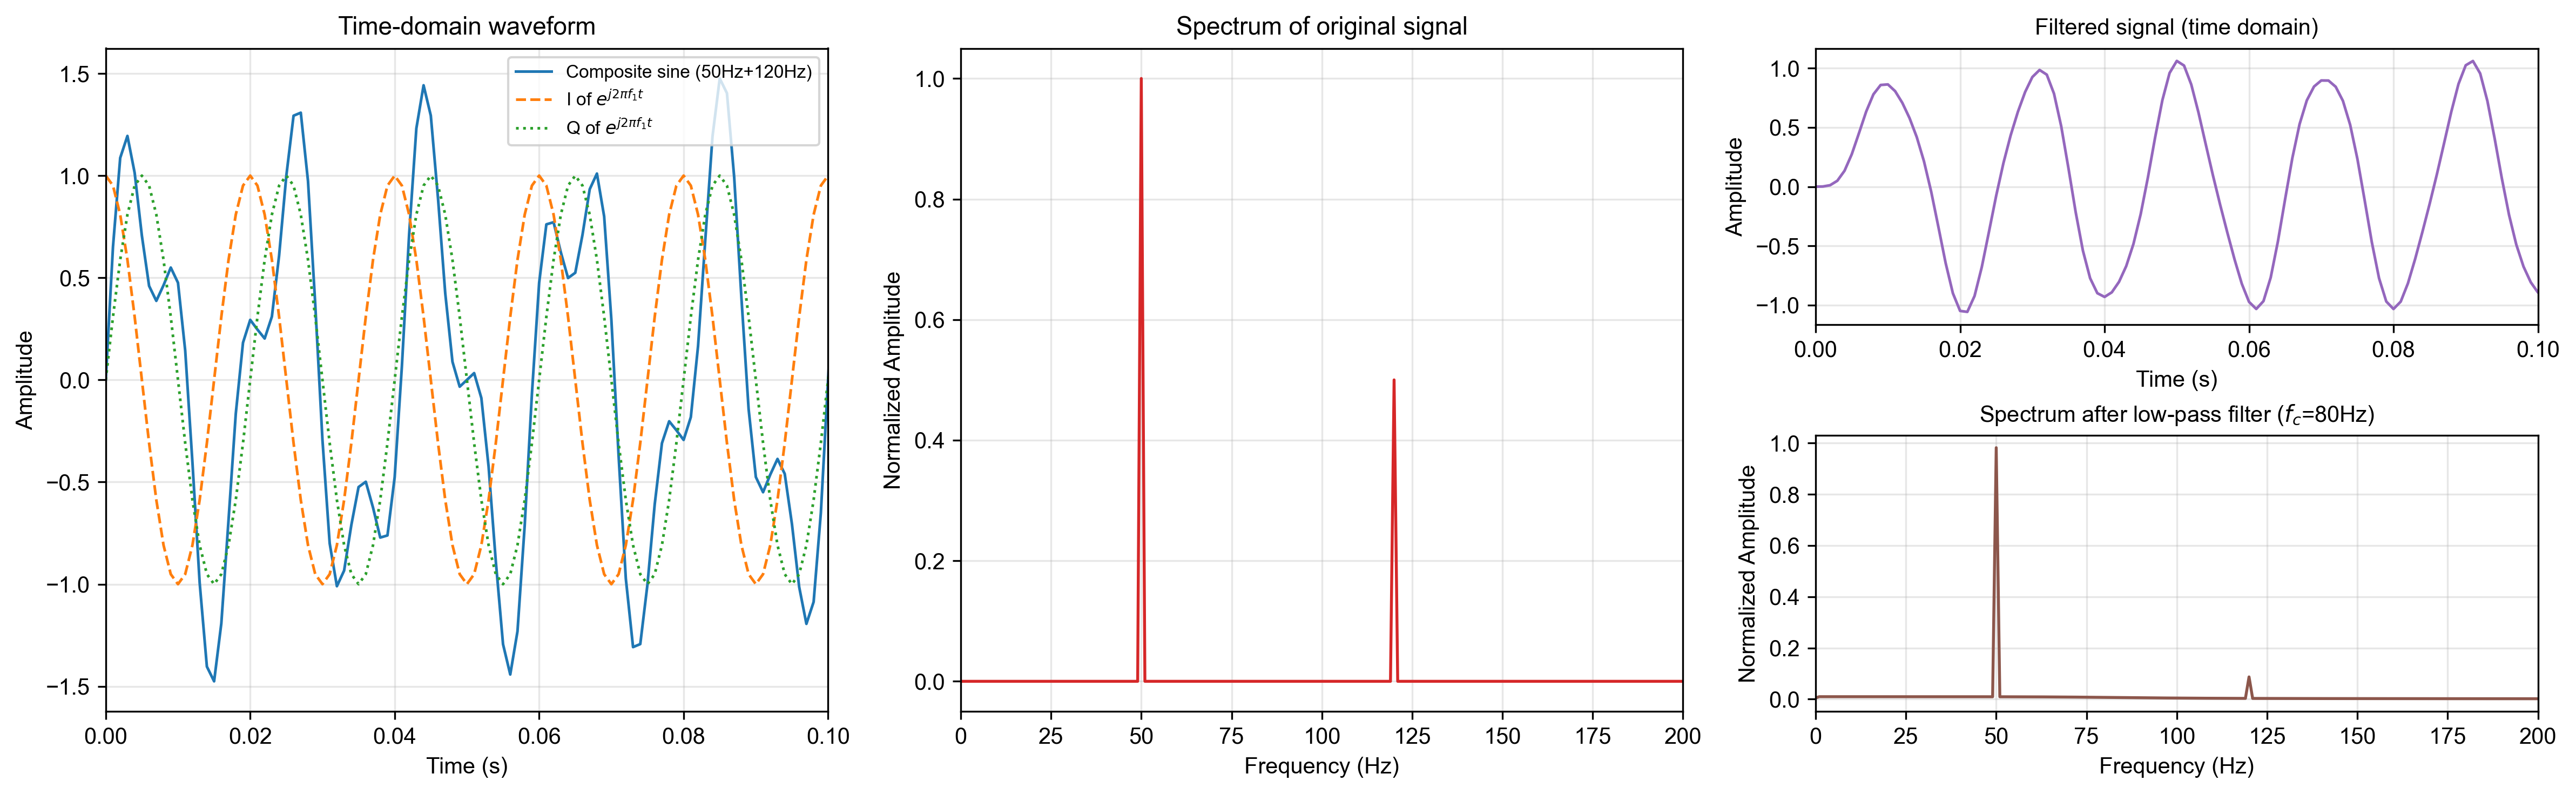

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ===================== 1. 参数设置（重点！和采样定理对应） =====================
fs = 1000        # 采样频率 Hz
duration = 1     # 信号时长 s
t = np.linspace(0, duration, int(fs * duration), endpoint=False)

f1 = 50          # 第一个信号频率 50Hz
f2 = 120         # 第二个信号频率 120Hz

# 生成【实正弦信号】：50Hz + 120Hz 叠加
x_sin = np.sin(2 * np.pi * f1 * t) + 0.5 * np.sin(2 * np.pi * f2 * t)

# 生成【复指数信号 e^(j*2π*f1*t)】，I路=实部cos，Q路=虚部sin，对应欧拉公式
x_complex = np.exp(1j * 2 * np.pi * f1 * t)
I = np.real(x_complex)
Q = np.imag(x_complex)

# ===================== 2. FFT 函数封装（以后直接复用，论文标准频谱） =====================
def compute_fft(sig, fs):
    N = len(sig)
    fft_vals = np.fft.fft(sig)
    fft_freq = np.fft.fftfreq(N, 1/fs)
    # 幅度归一化，单边谱（只取正频率）
    amp = np.abs(fft_vals) / N
    # 对于实信号，除直流，要×2
    amp[1:-1] = amp[1:-1] * 2
    # 挑出正频率
    mask = fft_freq >= 0
    return fft_freq[mask], amp[mask]

# 原始正弦信号频谱
freq_raw, amp_raw = compute_fft(x_sin, fs)

# ===================== 3. 设计低通滤波器 scipy.signal（巴特沃斯低通） =====================
cutoff = 80     # 截止频率80Hz：保留50Hz，滤掉120Hz
order = 4       # 滤波器阶数
b, a = signal.butter(order, cutoff, btype='lowpass', fs=fs)

# 信号滤波
x_filtered = signal.lfilter(b, a, x_sin)
freq_filt, amp_filt = compute_fft(x_filtered, fs)

# ===================== 4. 论文风格绘图！1行3张子图 =====================
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

fig = plt.figure(figsize=(16, 5), dpi=300)  # dpi=300 高清，适合论文插入

# -------- Subplot 1：时域波形，原始信号（正弦叠加 + I/Q复指数信号） --------
ax1 = fig.add_subplot(1, 3, 1)
ax1.plot(t, x_sin, color='#1f77b4', linewidth=1.2, label='Composite sine (50Hz+120Hz)')
ax1.plot(t, I, color='#ff7f0e', linewidth=1.2, linestyle='--', label='I of $e^{j2\pi f_1 t}$')
ax1.plot(t, Q, color='#2ca02c', linewidth=1.2, linestyle=':', label='Q of $e^{j2\pi f_1 t}$')
ax1.set_xlabel('Time (s)', fontsize=10)
ax1.set_ylabel('Amplitude', fontsize=10)
ax1.set_title('Time-domain waveform', fontsize=11)
ax1.legend(fontsize=8)
ax1.set_xlim(0, 0.1)  # 只画前0.1秒，波形挤在一起看不清

# -------- Subplot 2：原始信号频谱 --------
ax2 = fig.add_subplot(1, 3, 2)
ax2.plot(freq_raw, amp_raw, color='#d62728', linewidth=1.3)
ax2.set_xlabel('Frequency (Hz)', fontsize=10)
ax2.set_ylabel('Normalized Amplitude', fontsize=10)
ax2.set_title('Spectrum of original signal', fontsize=11)
ax2.set_xlim(0, 200)  # 只看0~200Hz，聚焦我们的频率点

# -------- Subplot3：滤波之后：上下两小图，上时域、下频谱 --------
# 我们用 subplot 里面再拆分，或者用 subgridspec
gs = fig.add_gridspec(1,3)
gs3 = gs[2].subgridspec(2,1, hspace=0.4)

ax3_top = fig.add_subplot(gs3[0])
ax3_top.plot(t, x_filtered, color='#9467bd', linewidth=1.2)
ax3_top.set_xlabel('Time (s)', fontsize=10)
ax3_top.set_ylabel('Amplitude', fontsize=10)
ax3_top.set_title('Filtered signal (time domain)', fontsize=10)
ax3_top.set_xlim(0,0.1)

ax3_bot = fig.add_subplot(gs3[1])
ax3_bot.plot(freq_filt, amp_filt, color='#8c564b', linewidth=1.3)
ax3_bot.set_xlabel('Frequency (Hz)', fontsize=10)
ax3_bot.set_ylabel('Normalized Amplitude', fontsize=10)
ax3_bot.set_title('Spectrum after low-pass filter ($f_c$=80Hz)', fontsize=10)
ax3_bot.set_xlim(0,200)

plt.tight_layout()
plt.savefig('signal_fft_filter.png', bbox_inches='tight')
plt.show()
